# Quantile Regression Random Forest 示例（格点）

本 notebook 演示 **分位数回归随机森林** 如何用历史集合预报 + 实况学习偏差，再输出条件分位数场。

**你会看到什么**

1. 读入 meteva 六维格点（`member, level, time, dtime, lat, lon`）
2. 用集合平均、标准差等特征训练模型
3. 输出 `0.1 / 0.5 / 0.9` 三个分位场，并用**同一色标**画图对比
4. 对比订正前后相对实况的误差

示例数据在 `quantile_regression_random_forest/testdata`：预报相对实况大约偏高 2°C。更完整的算法说明见同目录 `quantile_regression_random_forest.md`。


In [15]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import meteva_base
import numpy as np
import pandas as pd

cwd = Path.cwd().resolve()
repo = cwd if (cwd / "quantile_regression_random_forest").is_dir() else cwd.parent.parent
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

from quantile_regression_random_forest.src.quantile_regression_random_forest import apply_qrf, train_qrf

# 图内标题用英文短标签，避免部分 Windows 中文字体在连续多图时崩溃。
plt.rcParams["axes.unicode_minus"] = False

testdata = repo / "quantile_regression_random_forest" / "testdata"
forecast = meteva_base.read_griddata_from_nc(str(testdata / "forecast_grid.nc"))
truth = meteva_base.read_griddata_from_nc(str(testdata / "truth_grid.nc"))
feature_config = {"air_temperature": ["mean", "std"]}

print(forecast.dims, dict(forecast.sizes))
print("dtime_units =", forecast.attrs.get("dtime_units"))
print("起报", forecast.time.values, "时效", forecast.dtime.values)
print("实况有效时间", truth.time.values)

('member', 'level', 'time', 'dtime', 'lat', 'lon') {'member': 4, 'level': 1, 'time': 2, 'dtime': 1, 'lat': 12, 'lon': 12}
dtime_units = hour
起报 ['2024-01-01T00:00:00.000000000' '2024-01-01T12:00:00.000000000'] 时效 [6]
实况有效时间 ['2024-01-01T06:00:00.000000000' '2024-01-01T18:00:00.000000000']


## 读数说明

- `forecast`：集合预报，`member` 是集合成员；`time` 是起报时间，`dtime` 是时效
- `truth`：实况格点；这里 `dtime=0`，`time` 直接表示观测有效时间（= 起报 + 时效）
- `feature_config`：告诉算法对 `air_temperature` 取成员 `mean`、`std` 作为特征

下面先准备一个小工具：多个场画在一起时共用一套 `vmin/vmax` 和一根 colorbar，避免色标不一致造成“看起来差别很大、其实只是色标不同”。


In [16]:
def field_2d(data, time_index=0):
    item = data
    if "time" in item.dims and item.sizes.get("time", 1) > 1:
        item = item.isel(time=time_index)
    for dim in ("member", "level", "dtime", "time"):
        if dim in item.dims and item.sizes.get(dim, 1) == 1:
            item = item.isel({dim: 0})
    return item.transpose("lat", "lon")


def shared_panel(fields, titles, cmap="RdYlBu_r", units="degC", title=None, ncols=None, note=None):
    """画多场并共用色标；note 会 print 在图片正上方，方便对照阅读。"""
    if note:
        print(note)
    arrays = [np.asarray(field_2d(item) if hasattr(item, "dims") else item, dtype=float) for item in fields]
    finite = np.concatenate([arr.ravel() for arr in arrays])
    finite = finite[np.isfinite(finite)]
    vmin, vmax = float(finite.min()), float(finite.max())
    if np.isclose(vmin, vmax):
        vmax = vmin + 1.0

    n = len(fields)
    ncols = ncols or min(n, 3)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.6 * nrows), squeeze=False)
    last_im = None
    for index, (src, subtitle) in enumerate(zip(fields, titles)):
        ax = axes[index // ncols][index % ncols]
        plot = field_2d(src) if hasattr(src, "dims") else src
        last_im = ax.pcolormesh(
            np.asarray(plot.lon),
            np.asarray(plot.lat),
            np.asarray(plot),
            shading="auto",
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
        )
        ax.set_title(subtitle)
        ax.set_xlabel("lon")
        ax.set_ylabel("lat")
        ax.set_aspect("equal", adjustable="box")
    for index in range(n, nrows * ncols):
        axes[index // ncols][index % ncols].axis("off")
    cbar = fig.colorbar(last_im, ax=axes.ravel().tolist(), fraction=0.046, pad=0.04)
    cbar.set_label(units)
    if title:
        fig.suptitle(title)
    print(f"色标范围: vmin={vmin:.3f}, vmax={vmax:.3f} ({units})")
    plt.show()
    plt.close("all")
    return vmin, vmax


## 原始集合场

订正前先看一眼第一个起报时次：

- 四个成员场：空间结构相近，数值有成员离散
- 集合平均 / 标准差：平均场反映主信号，标准差反映局地不确定性

这些图已经用统一色标，方便后面和订正结果对照。


【图】订正前四个集合成员场：空间型相近，数值有成员差；色标统一，可直接比冷暖。
色标范围: vmin=6.700, vmax=40.346 (degC)


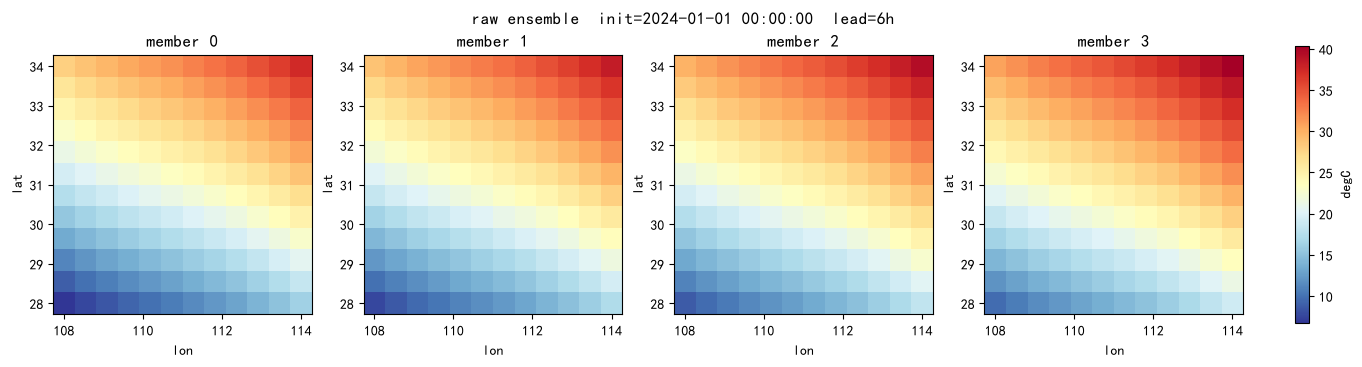

【图】左：集合平均（主信号）；右：成员标准差（局地离散度）。
色标范围: vmin=1.118, vmax=38.846 (degC)


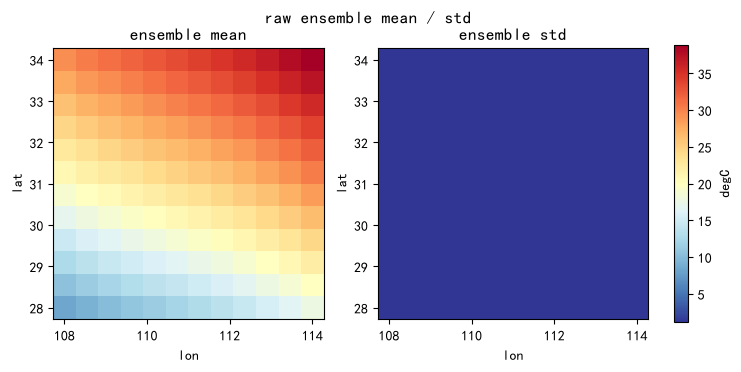

(1.1180331707000732, 38.84640121459961)

In [17]:
cycle0 = forecast.isel(time=0)
member_fields = [cycle0.sel(member=str(m)).squeeze(drop=True) for m in cycle0.member.values]
shared_panel(
    member_fields,
    [f"member {m}" for m in cycle0.member.values],
    title=f"raw ensemble  init={pd.Timestamp(cycle0.time.values)}  lead={int(cycle0.dtime.values)}h",
    ncols=4,
    note="【图】订正前四个集合成员场：空间型相近，数值有成员差；色标统一，可直接比冷暖。",
)

ens_mean = cycle0.mean("member")
ens_std = cycle0.std("member")
shared_panel(
    [ens_mean, ens_std],
    ["ensemble mean", "ensemble std"],
    title="raw ensemble mean / std",
    ncols=2,
    note="【图】左：集合平均（主信号）；右：成员标准差（局地离散度）。",
)


## 训练与订正

`train_qrf`：用全部格点样本（每个 lat/lon 当作一个“站点”）拟合分位数回归森林。  
`apply_qrf`：对同一份预报输出指定分位数。

输出仍是六维格点，但原来的集合成员维会被换成分位数；格点上 `member` 坐标写成 `"0.1"`、`"0.5"`、`"0.9"` 这样的字符串。起报时间、时效、层次和经纬度保持与输入预报一致。


In [18]:
quantiles = [0.1, 0.5, 0.9]
print("开始训练：每个格点当作一个站点，特征为集合 mean/std。")
bundle = train_qrf(
    forecast,
    truth,
    feature_config,
    target_name="air_temperature",
    n_estimators=40,
    random_state=0,
)
calibrated = apply_qrf(bundle, forecast, quantiles=quantiles)
print("订正完成。输出仍是六维格点，但 member 维已换成百分位数。")
print("维度/尺寸:", calibrated.dims, dict(calibrated.sizes))
print("分位成员:", list(calibrated.member.values))
print("中位数场均值:", float(calibrated.sel(member="0.5").mean()))


开始训练：每个格点当作一个站点，特征为集合 mean/std。
订正完成。输出仍是六维格点，但 member 维已换成百分位数。
维度/尺寸: ('member', 'level', 'time', 'dtime', 'lat', 'lon') {'member': 3, 'level': 1, 'time': 2, 'dtime': 1, 'lat': 12, 'lon': 12}
分位成员: [np.str_('0.1'), np.str_('0.5'), np.str_('0.9')]
中位数场均值: 23.40747833251953


## 多分位场（同一图例）

把 `q=0.1`、`q=0.5`、`q=0.9` 并排绘制，并强制共用一根色标：

- 低分位偏冷、高分位偏暖是正常的
- 若三张图色调接近，说明该时次订正后的分位间距不大
- 若有第二个起报时次，下面会再画一组，便于看时间变化


【图】同一起报时次的 0.1/0.5/0.9 分位场，强制同一色标：左冷右暖属正常，色差反映分位间距。
色标范围: vmin=6.200, vmax=36.846 (degC)


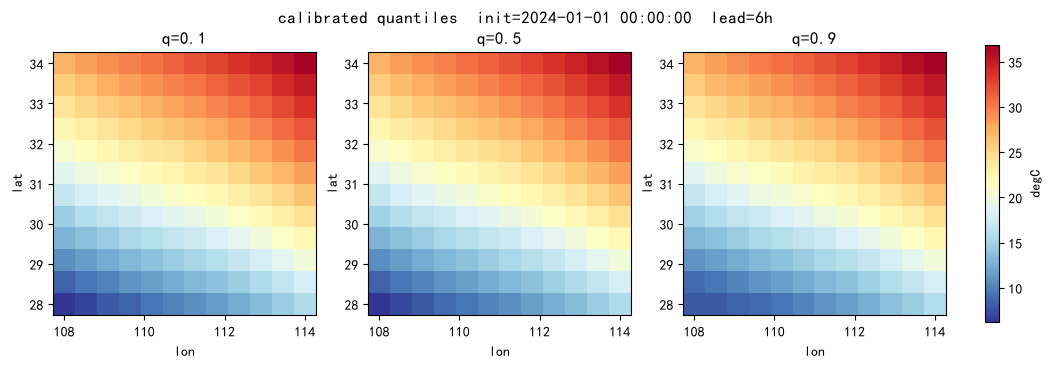

【图】第二个起报时次的三分位场，仍用统一色标，便于看时间变化。
色标范围: vmin=9.200, vmax=39.846 (degC)


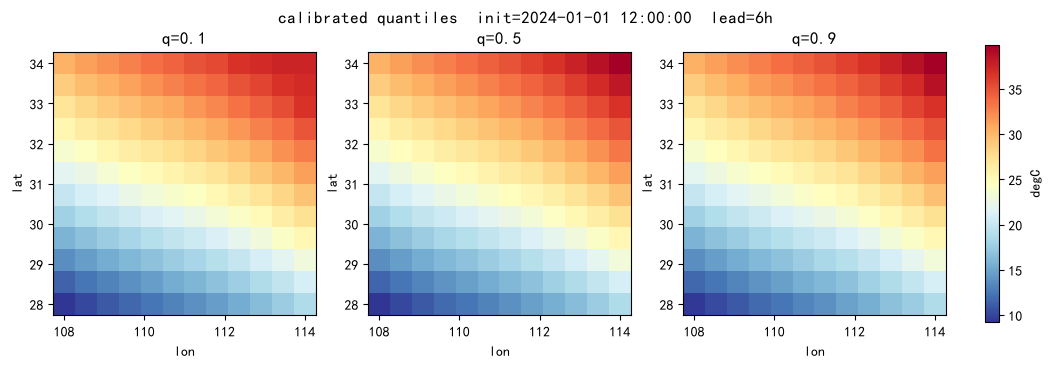

In [19]:
time_index = 0
q_fields = [
    calibrated.sel(member=f"{q:g}").isel(time=time_index).squeeze(drop=True)
    for q in quantiles
]
shared_panel(
    q_fields,
    [f"q={q:g}" for q in quantiles],
    title=f"calibrated quantiles  init={pd.Timestamp(calibrated.time.values[time_index])}  lead={int(calibrated.dtime.values[0])}h",
    note="【图】同一起报时次的 0.1/0.5/0.9 分位场，强制同一色标：左冷右暖属正常，色差反映分位间距。",
)

if calibrated.sizes["time"] > 1:
    q_fields_t1 = [
        calibrated.sel(member=f"{q:g}").isel(time=1).squeeze(drop=True)
        for q in quantiles
    ]
    shared_panel(
        q_fields_t1,
        [f"q={q:g}" for q in quantiles],
        title=f"calibrated quantiles  init={pd.Timestamp(calibrated.time.values[1])}  lead={int(calibrated.dtime.values[0])}h",
        note="【图】第二个起报时次的三分位场，仍用统一色标，便于看时间变化。",
    )


## 订正前后与实况对比

第一组图（同一色标）：

1. 订正前集合平均
2. 订正后中位数 `q=0.5`
3. 实况

第二组图（共用对称发散色标）：

- 订正前误差 = 集合平均 − 实况
- 订正后误差 = 中位数 − 实况

示例数据里订正前 MAE 大约是 2°C；订正后应明显下降。


【图】订正前平均 | 订正后中位数 | 实况。三场同一色标，看中位数是否更接近实况。
色标范围: vmin=6.200, vmax=38.846 (degC)


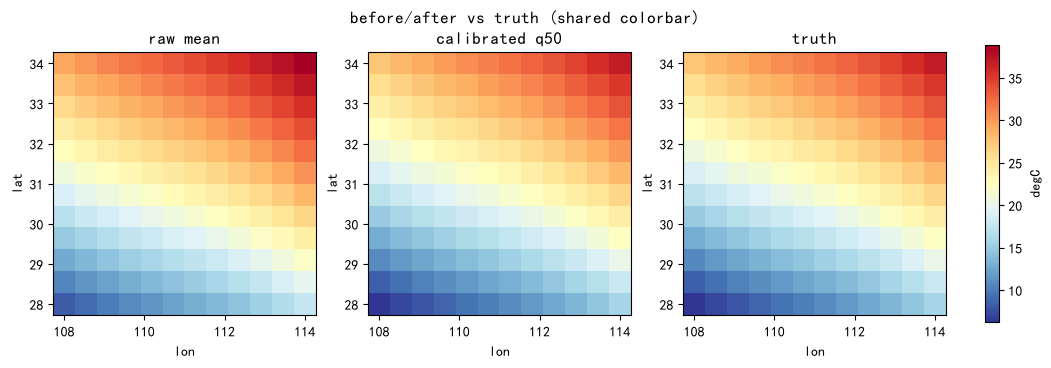

【图】误差场（集合平均-实况 vs 中位数-实况），共用对称色标。 MAE: 订正前 2.000 → 订正后 0.001


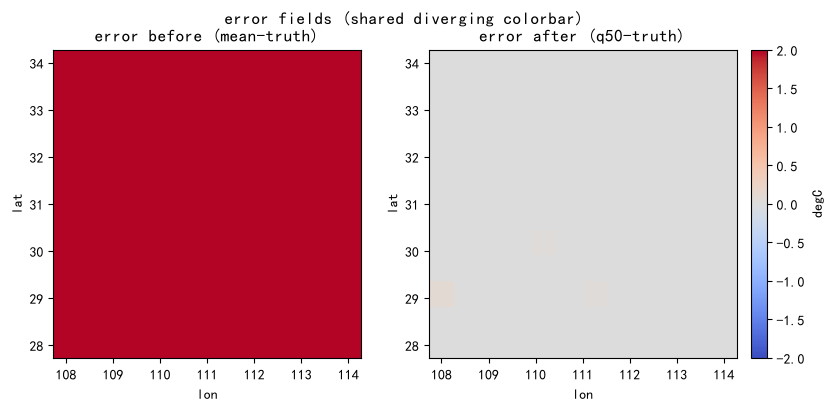

In [20]:
raw_mean = field_2d(forecast.mean("member"), time_index)
median = field_2d(calibrated.sel(member="0.5"), time_index)
truth_field = field_2d(truth.isel(member=0), time_index)

shared_panel(
    [raw_mean, median, truth_field],
    ["raw mean", "calibrated q50", "truth"],
    title="before/after vs truth (shared colorbar)",
    note="【图】订正前平均 | 订正后中位数 | 实况。三场同一色标，看中位数是否更接近实况。",
)

err_before = raw_mean.copy(data=raw_mean.values - truth_field.values)
err_after = median.copy(data=median.values - truth_field.values)
limit = float(np.nanmax(np.abs(np.stack([err_before.values, err_after.values]))))
mae_before = float(np.abs(err_before).mean())
mae_after = float(np.abs(err_after).mean())
print(
    "【图】误差场（集合平均-实况 vs 中位数-实况），共用对称色标。"
    f" MAE: 订正前 {mae_before:.3f} → 订正后 {mae_after:.3f}"
)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.0))
for ax, field, subtitle in zip(
    axes,
    [err_before, err_after],
    ["error before (mean-truth)", "error after (q50-truth)"],
):
    im = ax.pcolormesh(
        field.lon,
        field.lat,
        field,
        shading="auto",
        cmap="coolwarm",
        vmin=-limit,
        vmax=limit,
    )
    ax.set_title(subtitle)
    ax.set_xlabel("lon")
    ax.set_ylabel("lat")
    ax.set_aspect("equal", adjustable="box")
fig.colorbar(im, ax=axes, fraction=0.045, pad=0.02, label="degC")
fig.suptitle("error fields (shared diverging colorbar)")
plt.show()
plt.close("all")


## 分位间距与点对点诊断

- `q90 - q10`：订正后不确定度宽度，色标单独一套（量级不同于温度本身）
- 散点图：横轴实况，纵轴预报；点越靠近 1:1 线越好
- 右侧曲线：按实况排序后画出 q10/q50/q90 与实况，检查分位是否包住观测、中位数是否跟随实况

到这里就完成了“读数 → 训练 → 分位输出 → 可视化检验”的一整条路径。


【图】复查三分位场（同一色标）。
色标范围: vmin=6.200, vmax=36.846 (degC)


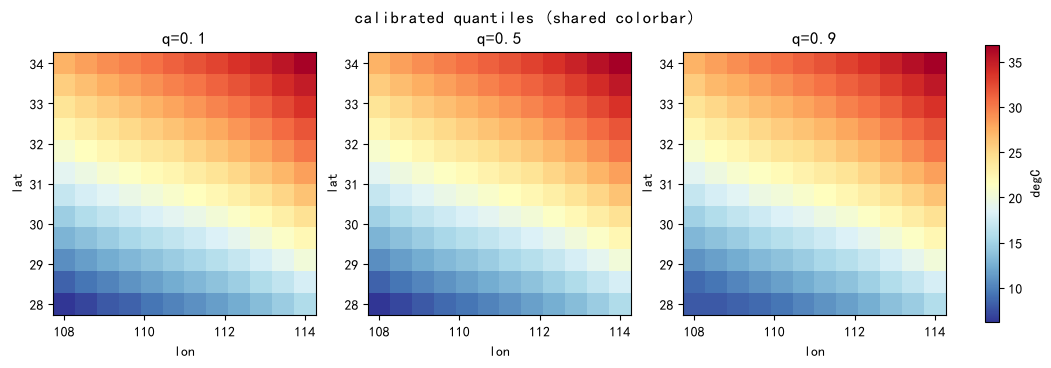

【图】分位间距 q90-q10：表示订正后的不确定度宽度（色标单独一套）。
色标范围: vmin=0.000, vmax=1.761 (degC)


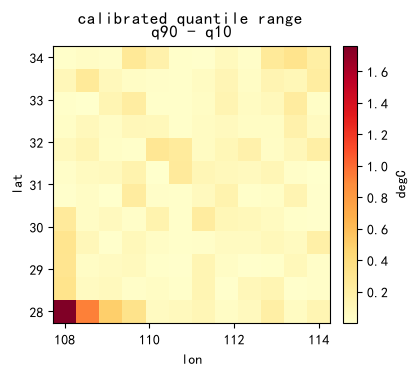

【图】左：实况 vs 预报散点（越靠近 1:1 线越好）；右：按实况排序后的 q10/q50/q90 曲线。


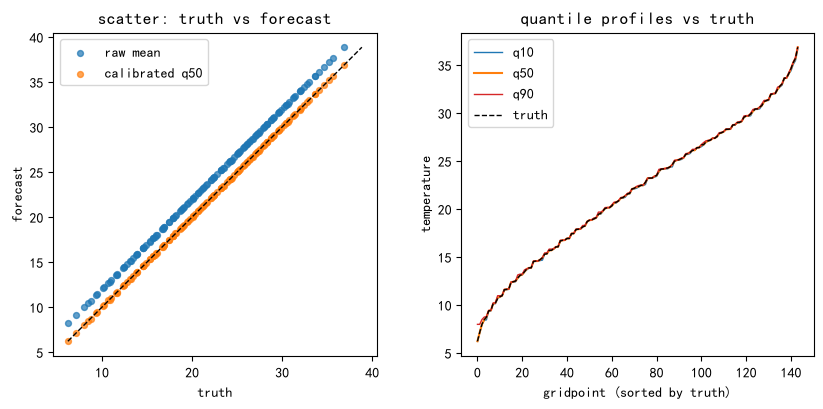

In [21]:
q10 = field_2d(calibrated.sel(member="0.1"), time_index)
q50 = field_2d(calibrated.sel(member="0.5"), time_index)
q90 = field_2d(calibrated.sel(member="0.9"), time_index)
spread = q90 - q10
shared_panel(
    [q10, q50, q90],
    ["q=0.1", "q=0.5", "q=0.9"],
    title="calibrated quantiles (shared colorbar)",
    note="【图】复查三分位场（同一色标）。",
)
shared_panel(
    [spread],
    ["q90 - q10"],
    cmap="YlOrRd",
    title="calibrated quantile range",
    note="【图】分位间距 q90-q10：表示订正后的不确定度宽度（色标单独一套）。",
)

obs = truth_field.values.ravel()
print("【图】左：实况 vs 预报散点（越靠近 1:1 线越好）；右：按实况排序后的 q10/q50/q90 曲线。")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].scatter(obs, raw_mean.values.ravel(), s=18, alpha=0.7, label="raw mean")
axes[0].scatter(obs, q50.values.ravel(), s=18, alpha=0.7, label="calibrated q50")
lims = [
    float(min(obs.min(), raw_mean.min(), q50.min())),
    float(max(obs.max(), raw_mean.max(), q50.max())),
]
axes[0].plot(lims, lims, "k--", linewidth=1)
axes[0].set_xlabel("truth")
axes[0].set_ylabel("forecast")
axes[0].set_title("scatter: truth vs forecast")
axes[0].legend()
axes[0].set_aspect("equal", adjustable="box")

order = np.argsort(obs)
x = np.arange(len(order))
axes[1].plot(x, q10.values.ravel()[order], color="tab:blue", linewidth=1.0, label="q10")
axes[1].plot(x, q50.values.ravel()[order], color="tab:orange", linewidth=1.5, label="q50")
axes[1].plot(x, q90.values.ravel()[order], color="tab:red", linewidth=1.0, label="q90")
axes[1].plot(x, obs[order], "k--", linewidth=1.0, label="truth")
axes[1].set_xlabel("gridpoint (sorted by truth)")
axes[1].set_ylabel("temperature")
axes[1].set_title("quantile profiles vs truth")
axes[1].legend()
plt.show()
plt.close("all")
